# 04 - Visualizações para o relatório executivo

Lê as tabelas da camada Gold (`datahackers_gold`) e gera os gráficos de cada pergunta do roteiro.
Salvo em PNG em `s3://teste-fiap-fase3/relatorio/graficos/`.

**Padrão visual**
- Formato 16:9 (slide), título com a conclusão e subtítulo com o contexto.
- Azul-marinho como cor principal, rosa para destacar o ponto mais importante e cinzas para as edições anteriores.
- Valores escritos nas barras, sem eixos e legendas desnecessários, e fonte em todos os gráficos.

## 1. Configuração da sessão

In [5]:
%idle_timeout 30
%glue_version 5.0
%worker_type G.1X
%number_of_workers 2

Welcome to the Glue Interactive Sessions Kernel
For more information on available magic commands, please type %help in any new cell.

Please view our Getting Started page to access the most up-to-date information on the Interactive Sessions kernel: https://docs.aws.amazon.com/glue/latest/dg/interactive-sessions.html
Installed kernel version: 1.0.10 
Current idle_timeout is None minutes.
idle_timeout has been set to 30 minutes.
Setting Glue version to: 5.0
Previous worker type: None
Setting new worker type to: G.1X
Previous number of workers: None
Setting new number of workers to: 2


## 2. Contexto Spark e bibliotecas

In [1]:
import textwrap

import boto3
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import pandas as pd
from pyspark.context import SparkContext
from pyspark.sql import functions as F
from awsglue.context import GlueContext

sc = SparkContext.getOrCreate()
glueContext = GlueContext(sc)
spark = glueContext.spark_session

BUCKET = "teste-fiap-fase3"
DATABASE_GOLD = "datahackers_gold"
PREFIXO_GRAFICOS = "relatorio/graficos/"
s3 = boto3.client("s3")

print("Sessão pronta para gerar os gráficos.")

Trying to create a Glue session for the kernel.
Session Type: glueetl
Worker Type: G.1X
Number of Workers: 2
Idle Timeout: 30
Session ID: 3c21a511-9a13-4fc8-9611-bf2c40a77478
Applying the following default arguments:
--glue_kernel_version 1.0.10
--enable-glue-datacatalog true
Waiting for session 3c21a511-9a13-4fc8-9611-bf2c40a77478 to get into ready status...
Session 3c21a511-9a13-4fc8-9611-bf2c40a77478 has been created.
Sessão pronta para gerar os gráficos.


## 3. Padrão visual

Funções para deixar os gráficos padronizados, com o mesmo visual:
- `barras_horizontais`: ranking em barras horizontais, do maior para o menor, com destaque no primeiro.
- `finalizar`: título, subtítulo e fonte, salva o PNG no S3.
- `gold`: lê uma tabela da Gold e devolve um DataFrame do pandas.

In [2]:
# Paleta
AZUL = "#1F3A5F"       
ROSA = "#ED145B"      
CINZA_CLARO = "#C9D1D9"
CINZA_MEDIO = "#7A8B99"
CINZA_TEXTO = "#5B6770"
PRETO = "#2B2B2B"

ANOS = ["2023", "2024", "2025-2026"]
ROTULO_ANO = {"2023": "2023", "2024": "2024", "2025-2026": "2025/26"}
COR_ANO = {"2023": CINZA_CLARO, "2024": CINZA_MEDIO, "2025-2026": AZUL}
RS = r"R\$"   
FONTE = "Fonte: State of Data Brazil (Data Hackers e Bain) - edições 2023, 2024 e 2025/26."

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 11,
    "axes.edgecolor": CINZA_CLARO,
    "axes.labelcolor": CINZA_TEXTO,
    "xtick.color": CINZA_TEXTO,
    "ytick.color": PRETO,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "figure.facecolor": "white",
})

def pct(valor):
    return f"{valor:.1f}%".replace(".", ",")

def quebrar(texto, largura=38):
    return textwrap.fill(str(texto), largura)

def gold(tabela):
    return spark.table(f"{DATABASE_GOLD}.gold_{tabela}").toPandas()

def barras_horizontais(ax, rotulos, valores, destaque=1, formato=pct):
    posicoes = list(range(len(valores)))[::-1]          # maior valor no topo
    cores = [ROSA if i < destaque else AZUL for i in range(len(valores))]
    ax.barh(posicoes, valores, color=cores, height=0.65)
    ax.set_yticks(posicoes)
    ax.set_yticklabels(rotulos)
    for y, v in zip(posicoes, valores):
        ax.text(v + max(valores) * 0.01, y, formato(v), va="center", fontsize=10, color=PRETO)
    ax.set_xlim(0, max(valores) * 1.15)
    ax.xaxis.set_visible(False)
    ax.spines["bottom"].set_visible(False)
    ax.spines["left"].set_visible(False)
    ax.tick_params(axis="y", length=0)

# Afasta rótulos que ficariam sobrepostos no fim das linhas.
def espacar(valores, distancia=4):
    ordem = sorted(range(len(valores)), key=lambda i: valores[i])
    ajustados = list(valores)
    for anterior, atual in zip(ordem, ordem[1:]):
        if ajustados[atual] - ajustados[anterior] < distancia:
            ajustados[atual] = ajustados[anterior] + distancia
    return ajustados

# Os nomes das opções conforme as colunas da pesquisa.
NOMES_TECNOLOGIAS = {
    "Sql": "SQL", "Javascript": "JavaScript", "Visual basic vba": "VBA", "Sas stata": "SAS/Stata",
    "C c c": "C/C++/C#", "Net": ".NET", "Matlab": "MATLAB", "Php": "PHP",
    "Amazon web services aws": "AWS", "Azure microsoft": "Azure", "Google cloud gcp": "Google Cloud",
    "Oracle cloud": "Oracle Cloud", "Ibm": "IBM", "Cloud propria": "Cloud própria",
    "Servidores on premise nao utilizamos cloud": "On-premise (sem cloud)",
    "Microsoft powerbi": "Power BI", "Looker studio google data studio": "Looker Studio",
    "Qlik view qlik sense": "Qlik", "Nao utilizo nenhuma ferramenta de bi no trabalho": "Não usa ferramenta de BI",
}
ACENTOS = {
    "nao": "não", "tecnico": "técnico", "tecnicos": "técnicos", "seguranca": "segurança", "saidas": "saídas",
    "alucinacao": "alucinação", "implementacao": "implementação", "negocio": "negócio", "direcao": "direção",
    "ve": "vê", "solucoes": "soluções", "producao": "produção", "decisao": "decisão", "informacoes": "informações",
    "propria": "própria", "areas": "áreas", "area": "área", "ja": "já", "sao": "são", "operacao": "operação",
    "automacao": "automação", "analise": "análise", "orcamento": "orçamento", "codigo": "código",
    "regulamentacao": "regulamentação", "experiencia": "experiência", "preocupacoes": "preocupações",
    "decisoes": "decisões", "inovacao": "inovação", "aplicacao": "aplicação", "aplicacoes": "aplicações",
    "otimizacao": "otimização", "integracao": "integração", "adocao": "adoção", "nivel": "nível",
    "acoes": "ações", "geracao": "geração", "conteudo": "conteúdo", "criacao": "criação",
    "organizacao": "organização", "proprio": "próprio", "estrategia": "estratégia", "estrategico": "estratégico",
    "praticas": "práticas", "metricas": "métricas", "tambem": "também", "juridicos": "jurídicos",
    "eticos": "éticos", "etica": "ética", "basico": "básico", "documentacao": "documentação",
    "programacao": "programação", "eficiencia": "eficiência", "precisao": "precisão", "mudanca": "mudança",
    "lideranca": "liderança", "informacao": "informação", "prioritario": "prioritário", "estao": "estão",
    "compreensao": "compreensão", "roi": "(ROI)", "ia": "IA", "ai": "IA",
    "llms": "LLMs", "llm": "LLM", "bi": "BI", "rh": "RH", "ti": "TI",
}

def rotulo(texto):
    if texto in NOMES_TECNOLOGIAS:
        return NOMES_TECNOLOGIAS[texto]
    palavras = [ACENTOS.get(p.lower(), p) for p in str(texto).split()]
    frase = " ".join(palavras)
    return frase[:1].upper() + frase[1:]

def finalizar(fig, titulo, subtitulo, arquivo, nota=None):
    fig.subplots_adjust(top=0.80, bottom=0.16)
   
    fig.canvas.draw()
    esquerda = fig.get_tightbbox(fig.canvas.get_renderer()).x0 / fig.get_figwidth()
    if esquerda < 0.02:
        fig.subplots_adjust(left=fig.subplotpars.left + (0.02 - esquerda))
    fig.text(0.02, 0.97, titulo, ha="left", va="top", fontsize=16, fontweight="bold", color=PRETO)
    fig.text(0.02, 0.895, subtitulo, ha="left", va="top", fontsize=11, color=CINZA_TEXTO)
    rodape = FONTE if nota is None else f"{nota}\n{FONTE}"
    fig.text(0.02, 0.02, rodape, ha="left", va="bottom", fontsize=8.5, color=CINZA_TEXTO)
    caminho_local = f"/tmp/{arquivo}.png"
    fig.savefig(caminho_local, dpi=200, bbox_inches="tight", facecolor="white")
    s3.upload_file(caminho_local, BUCKET, f"{PREFIXO_GRAFICOS}{arquivo}.png")
    print(f"Salvo em s3://{BUCKET}/{PREFIXO_GRAFICOS}{arquivo}.png")

print("Padrão visual definido.")

Padrão visual definido.


## 4. Q1 - Como está estruturado o mercado brasileiro de dados?

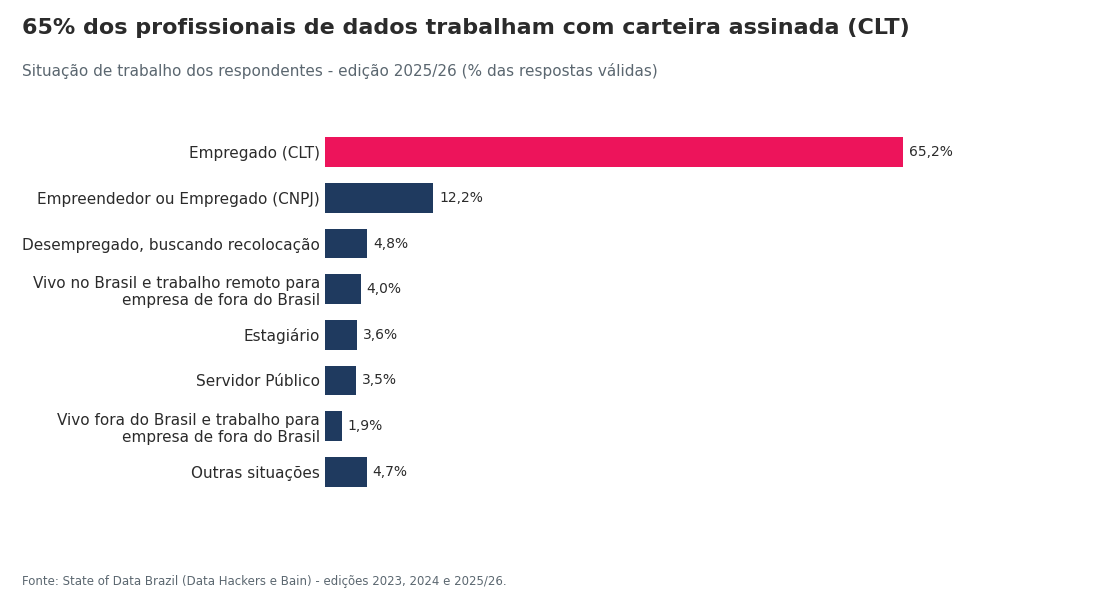

In [3]:
# Situação de trabalho na edição mais recente
estrutura = gold("estrutura_mercado")
df = (estrutura[(estrutura["indicador"] == "Situação de trabalho") & (estrutura["ano_pesquisa"] == "2025-2026")]
      .sort_values("percentual", ascending=False))

principais = df.head(7)
outras = df.iloc[7:]["percentual"].sum()
rotulos = [quebrar(c, 40) for c in principais["categoria"]] + ["Outras situações"]
valores = list(principais["percentual"]) + [outras]

clt = df.loc[df["categoria"] == "Empregado (CLT)", "percentual"].iloc[0]

fig, ax = plt.subplots(figsize=(11, 6))
barras_horizontais(ax, rotulos, valores)
finalizar(fig,
          f"{clt:.0f}% dos profissionais de dados trabalham com carteira assinada (CLT)",
          "Situação de trabalho dos respondentes - edição 2025/26 (% das respostas válidas)",
          "q1_situacao_trabalho")
%matplot plt

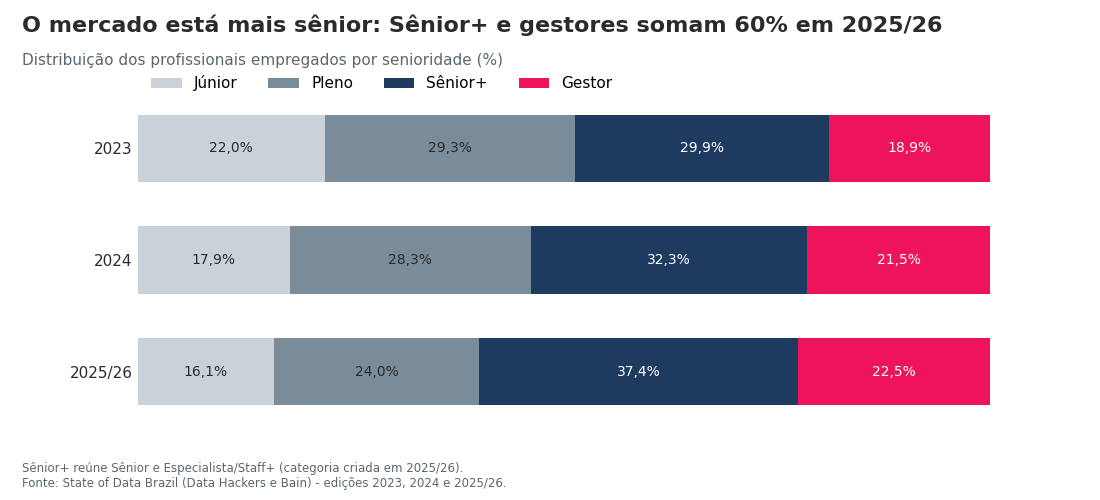

In [4]:
# Composição por senioridade em cada edição (barras 100% empilhadas)
niveis = ["Júnior", "Pleno", "Sênior+", "Gestor"]
cores_niveis = {"Júnior": CINZA_CLARO, "Pleno": CINZA_MEDIO, "Sênior+": AZUL, "Gestor": ROSA}

df = estrutura[estrutura["indicador"] == "Senioridade"]
tabela = df.pivot(index="ano_pesquisa", columns="categoria", values="percentual").reindex(ANOS)[niveis]

fig, ax = plt.subplots(figsize=(11, 5))
base = [0] * len(ANOS)
posicoes = list(range(len(ANOS)))[::-1]
for nivel in niveis:
    valores = tabela[nivel].tolist()
    ax.barh(posicoes, valores, left=base, color=cores_niveis[nivel], height=0.6, label=nivel)
    for y, inicio, v in zip(posicoes, base, valores):
        cor_texto = "white" if nivel in ("Sênior+", "Gestor") else PRETO
        ax.text(inicio + v / 2, y, pct(v), ha="center", va="center", fontsize=10, color=cor_texto)
    base = [b + v for b, v in zip(base, valores)]

ax.set_yticks(posicoes)
ax.set_yticklabels([ROTULO_ANO[a] for a in ANOS])
ax.set_xlim(0, 100)
ax.xaxis.set_visible(False)
ax.spines["bottom"].set_visible(False)
ax.spines["left"].set_visible(False)
ax.tick_params(axis="y", length=0)
ax.legend(ncol=4, loc="upper left", bbox_to_anchor=(0, 1.12), frameon=False)

senior_gestor = tabela.loc["2025-2026", "Sênior+"] + tabela.loc["2025-2026", "Gestor"]
finalizar(fig,
          f"O mercado está mais sênior: Sênior+ e gestores somam {senior_gestor:.0f}% em 2025/26",
          "Distribuição dos profissionais empregados por senioridade (%)",
          "q1_senioridade",
          nota="Sênior+ reúne Sênior e Especialista/Staff+ (categoria criada em 2025/26).")
%matplot plt

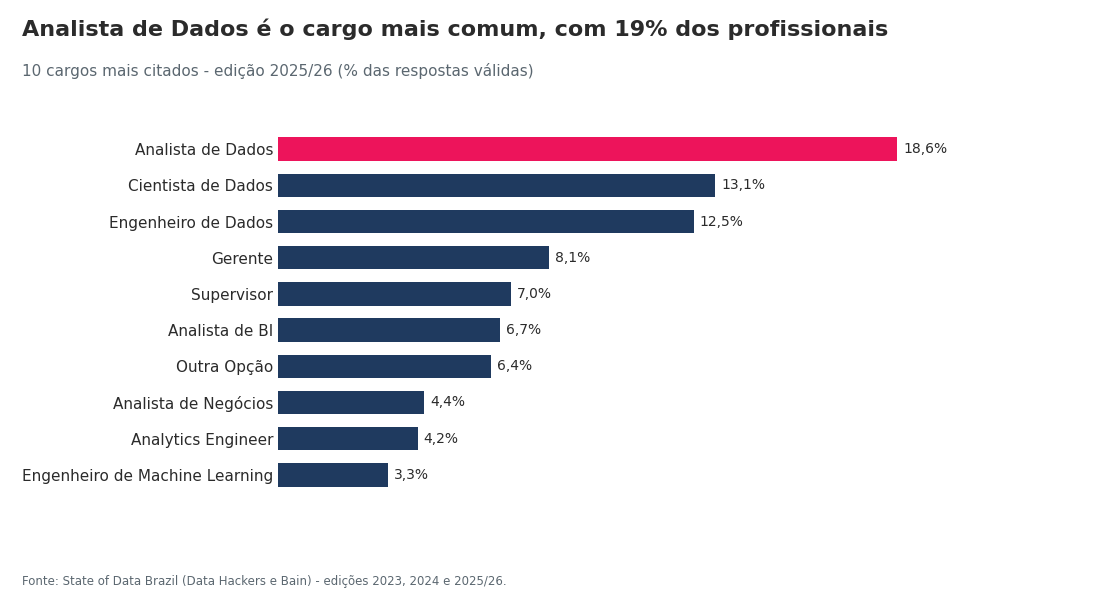

In [5]:
# Cargos mais comuns na edição mais recente
df = (estrutura[(estrutura["indicador"] == "Cargo") & (estrutura["ano_pesquisa"] == "2025-2026")]
      .sort_values("percentual", ascending=False).head(10))
rotulos = [c.split("/")[0].strip() for c in df["categoria"]]

fig, ax = plt.subplots(figsize=(11, 6))
barras_horizontais(ax, rotulos, df["percentual"].tolist())
finalizar(fig,
          f"{rotulos[0]} é o cargo mais comum, com {df['percentual'].iloc[0]:.0f}% dos profissionais",
          "10 cargos mais citados - edição 2025/26 (% das respostas válidas)",
          "q1_cargos")
%matplot plt

## 5. Q2 - Quais perfis profissionais são mais valorizados?

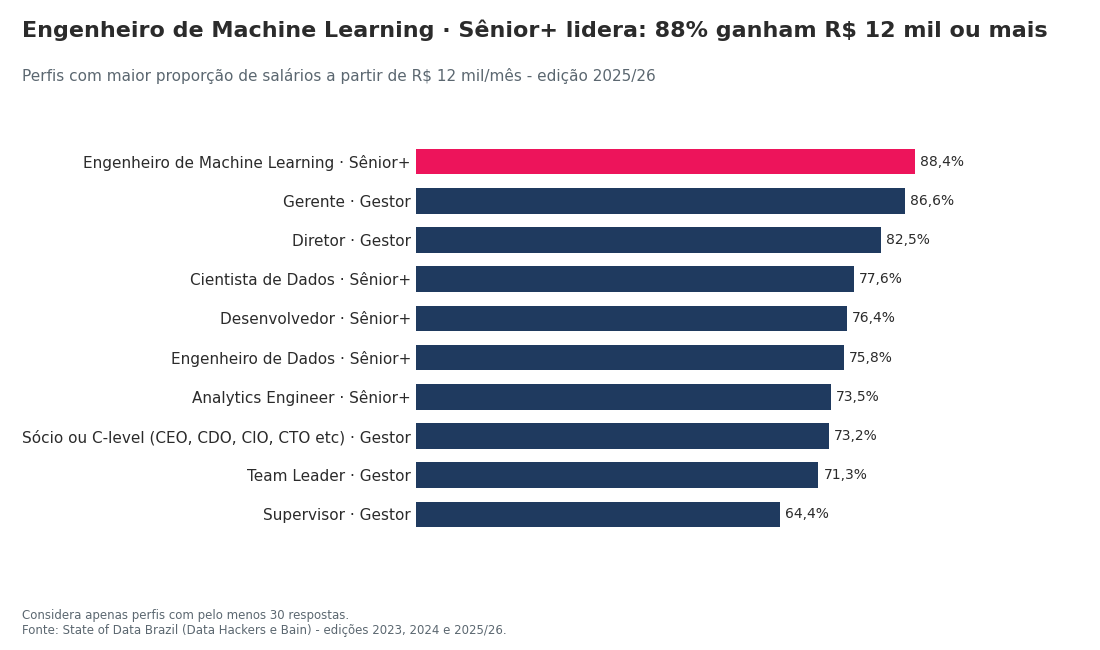

In [6]:
# Ranking de perfis (cargo x senioridade) pelo % que ganha R$ 12 mil ou mais
perfis = gold("remuneracao_perfis")
df = perfis[perfis["ano_pesquisa"] == "2025-2026"].sort_values("posicao").head(10)
rotulos = [f"{c.split('/')[0].strip()} · {s}" for c, s in zip(df["cargo"], df["senioridade_harmonizada"])]

fig, ax = plt.subplots(figsize=(11, 6.5))
barras_horizontais(ax, rotulos, df["pct_12k_mais"].tolist())
finalizar(fig,
          f"{rotulos[0]} lidera: {df['pct_12k_mais'].iloc[0]:.0f}% ganham {RS} 12 mil ou mais",
          f"Perfis com maior proporção de salários a partir de {RS} 12 mil/mês - edição 2025/26",
          "q2_perfis_valorizados",
          nota="Considera apenas perfis com pelo menos 30 respostas.")
%matplot plt

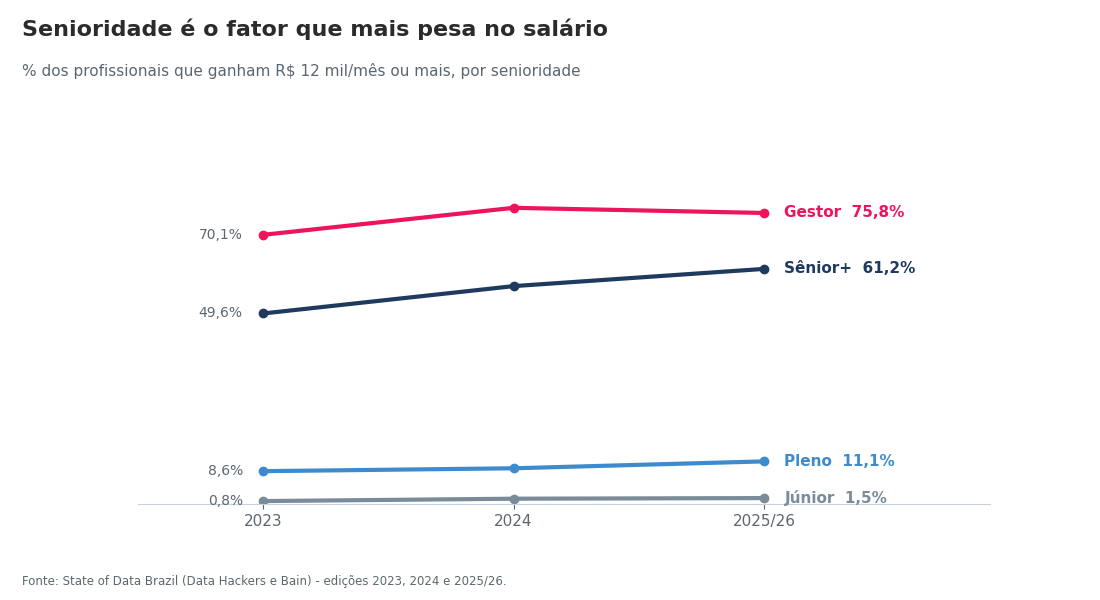

In [7]:
# Evolução do % que ganha R$ 12 mil ou mais, por senioridade
comparacoes = gold("comparacoes_remuneracao")
df = comparacoes[comparacoes["dimensao"] == "Senioridade"]
tabela = df.pivot(index="categoria", columns="ano_pesquisa", values="pct_12k_mais")[ANOS]
cores_niveis = {"Júnior": CINZA_MEDIO, "Pleno": "#3D8BCD", "Sênior+": AZUL, "Gestor": ROSA}

fig, ax = plt.subplots(figsize=(11, 6))
x = list(range(len(ANOS)))
niveis = ["Gestor", "Sênior+", "Pleno", "Júnior"]
fim = espacar([tabela.loc[n, "2025-2026"] for n in niveis])
inicio = espacar([tabela.loc[n, "2023"] for n in niveis])
for nivel, y_fim, y_inicio in zip(niveis, fim, inicio):
    valores = tabela.loc[nivel].tolist()
    ax.plot(x, valores, marker="o", linewidth=3, color=cores_niveis[nivel])
    ax.text(x[-1] + 0.08, y_fim, f"{nivel}  {pct(valores[-1])}", va="center",
            fontsize=11, color=cores_niveis[nivel], fontweight="bold")
    ax.text(x[0] - 0.08, y_inicio, pct(valores[0]), va="center", ha="right", fontsize=10, color=CINZA_TEXTO)

ax.set_xticks(x)
ax.set_xticklabels([ROTULO_ANO[a] for a in ANOS])
ax.set_xlim(-0.5, 2.9)
ax.set_ylim(0, 100)
ax.yaxis.set_visible(False)
ax.spines["left"].set_visible(False)

finalizar(fig,
          "Senioridade é o fator que mais pesa no salário",
          f"% dos profissionais que ganham {RS} 12 mil/mês ou mais, por senioridade",
          "q2_salario_senioridade")
%matplot plt

## 6. Q3 - Qual é o cenário de diversidade de gênero?

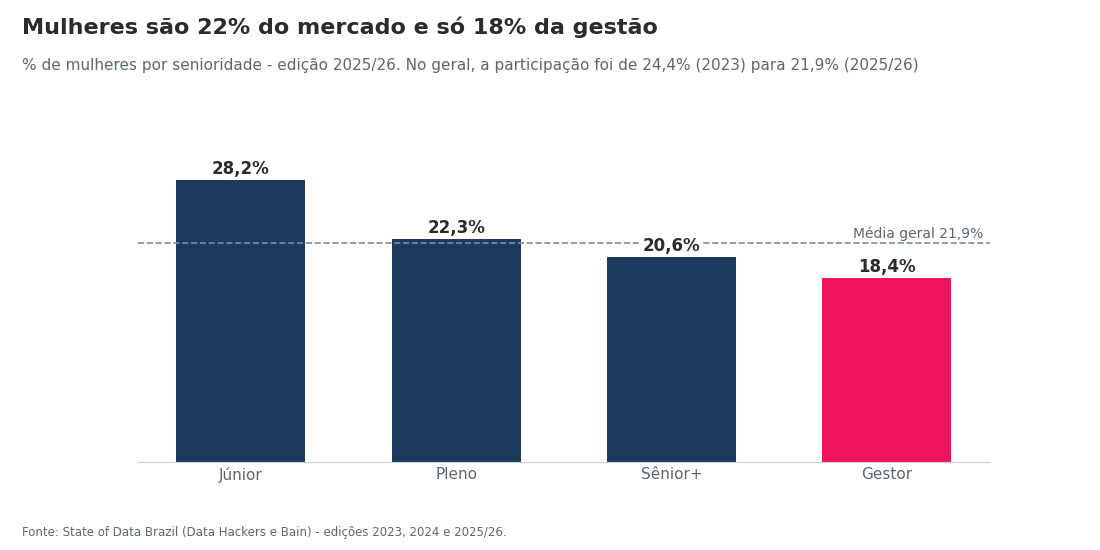

In [8]:
# Participação feminina no geral e por senioridade
diversidade = gold("diversidade_genero")
mulheres = diversidade[diversidade["genero"] == "Feminino"]
geral = mulheres[mulheres["recorte"] == "Geral"].set_index("ano_pesquisa")["percentual"]

ordem = ["Júnior", "Pleno", "Sênior+", "Gestor"]
df = mulheres[(mulheres["ano_pesquisa"] == "2025-2026") & (mulheres["recorte"].isin(ordem))]
df = df.set_index("recorte").reindex(ordem)

fig, ax = plt.subplots(figsize=(11, 5.5))
cores = [AZUL, AZUL, AZUL, ROSA]
ax.bar(ordem, df["percentual"], color=cores, width=0.6)
for i, v in enumerate(df["percentual"]):
    ax.text(i, v + 0.6, pct(v), ha="center", fontsize=12, fontweight="bold", color=PRETO,
            bbox=dict(facecolor="white", edgecolor="none", pad=1), zorder=3)
ax.axhline(geral["2025-2026"], color=CINZA_MEDIO, linestyle="--", linewidth=1.2, zorder=1)
ax.text(3.45, geral["2025-2026"] + 0.5, f"Média geral {pct(geral['2025-2026'])}", ha="right",
        fontsize=10, color=CINZA_TEXTO)
ax.set_ylim(0, df["percentual"].max() * 1.25)
ax.yaxis.set_visible(False)
ax.spines["left"].set_visible(False)
ax.tick_params(axis="x", length=0)

finalizar(fig,
          f"Mulheres são {geral['2025-2026']:.0f}% do mercado e só {df.loc['Gestor', 'percentual']:.0f}% da gestão",
          f"% de mulheres por senioridade - edição 2025/26. No geral, a participação foi de "
          f"{pct(geral['2023'])} (2023) para {pct(geral['2025-2026'])} (2025/26)",
          "q3_mulheres_senioridade")
%matplot plt

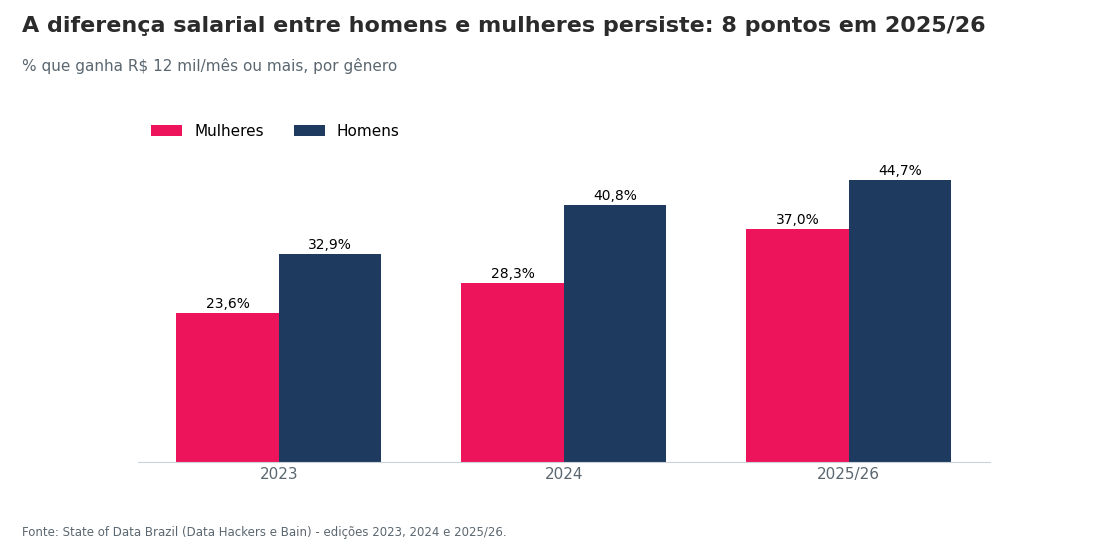

In [9]:
# Diferença salarial entre mulheres e homens
df = comparacoes[(comparacoes["dimensao"] == "Gênero") & (comparacoes["categoria"].isin(["Feminino", "Masculino"]))]
tabela = df.pivot(index="ano_pesquisa", columns="categoria", values="pct_12k_mais").reindex(ANOS)

fig, ax = plt.subplots(figsize=(11, 5.5))
x = list(range(len(ANOS)))
largura = 0.36
ax.bar([i - largura / 2 for i in x], tabela["Feminino"], width=largura, color=ROSA, label="Mulheres")
ax.bar([i + largura / 2 for i in x], tabela["Masculino"], width=largura, color=AZUL, label="Homens")
for i in x:
    ax.text(i - largura / 2, tabela["Feminino"].iloc[i] + 0.8, pct(tabela["Feminino"].iloc[i]), ha="center", fontsize=10)
    ax.text(i + largura / 2, tabela["Masculino"].iloc[i] + 0.8, pct(tabela["Masculino"].iloc[i]), ha="center", fontsize=10)
ax.set_xticks(x)
ax.set_xticklabels([ROTULO_ANO[a] for a in ANOS])
ax.set_ylim(0, tabela.max().max() * 1.25)
ax.yaxis.set_visible(False)
ax.spines["left"].set_visible(False)
ax.tick_params(axis="x", length=0)
ax.legend(loc="upper left", frameon=False, ncol=2)

diferenca = tabela.loc["2025-2026", "Masculino"] - tabela.loc["2025-2026", "Feminino"]
finalizar(fig,
          f"A diferença salarial entre homens e mulheres persiste: {diferenca:.0f} pontos em 2025/26",
          f"% que ganha {RS} 12 mil/mês ou mais, por gênero",
          "q3_diferenca_salarial_genero")
%matplot plt

## 7. Q4 - Quais tecnologias apresentam maior adoção?

A edição 2025/26 não tem a pergunta de linguagens usadas no dia a dia, por isso o gráfico de linguagens compara 2023 e 2024.

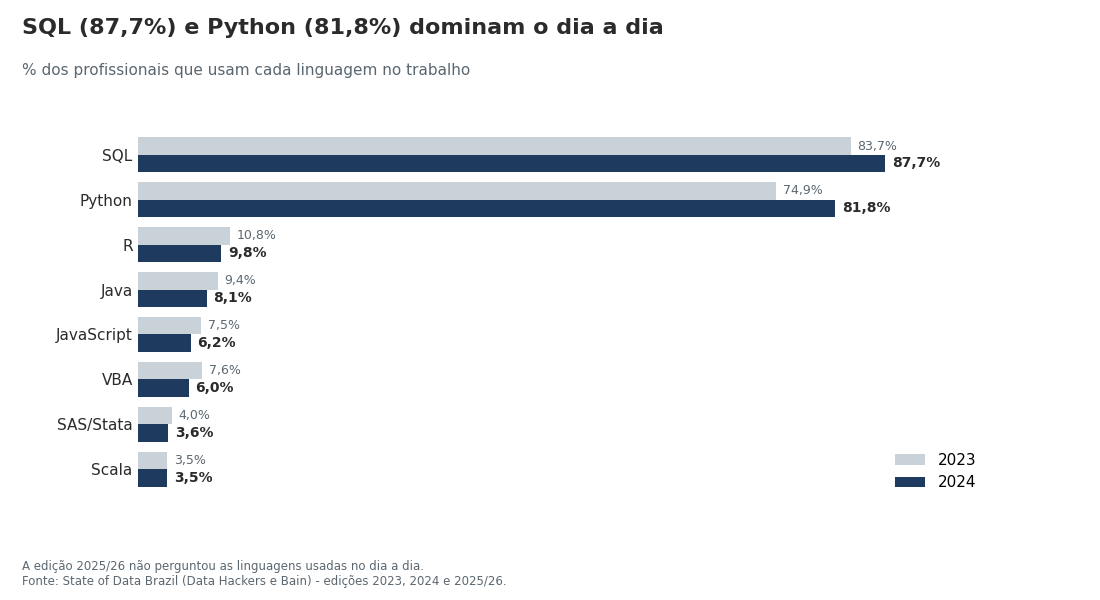

In [10]:
# Linguagens mais usadas no dia a dia (2023 x 2024)
tecnologias = gold("adocao_tecnologias")
df = tecnologias[(tecnologias["tema"] == "Linguagens") & (~tecnologias["tecnologia"].str.lower().str.startswith("nao utilizo"))]
tabela = df.pivot(index="tecnologia", columns="ano_pesquisa", values="percentual")
tabela = tabela.sort_values("2024", ascending=False).head(8)

fig, ax = plt.subplots(figsize=(11, 6))
posicoes = list(range(len(tabela)))[::-1]
altura = 0.38
ax.barh([p + altura / 2 for p in posicoes], tabela["2023"], height=altura, color=CINZA_CLARO, label="2023")
ax.barh([p - altura / 2 for p in posicoes], tabela["2024"], height=altura, color=AZUL, label="2024")
for p, v23, v24 in zip(posicoes, tabela["2023"], tabela["2024"]):
    ax.text(v23 + 0.8, p + altura / 2, pct(v23), va="center", fontsize=9, color=CINZA_TEXTO)
    ax.text(v24 + 0.8, p - altura / 2, pct(v24), va="center", fontsize=10, color=PRETO, fontweight="bold")
ax.set_yticks(posicoes)
ax.set_yticklabels([rotulo(t) for t in tabela.index])
ax.set_xlim(0, 100)
ax.xaxis.set_visible(False)
ax.spines["bottom"].set_visible(False)
ax.spines["left"].set_visible(False)
ax.tick_params(axis="y", length=0)
ax.legend(loc="lower right", frameon=False)

finalizar(fig,
          f"SQL ({pct(tabela.loc['Sql', '2024'])}) e Python ({pct(tabela.loc['Python', '2024'])}) dominam o dia a dia",
          "% dos profissionais que usam cada linguagem no trabalho",
          "q4_linguagens",
          nota="A edição 2025/26 não perguntou as linguagens usadas no dia a dia.")
%matplot plt

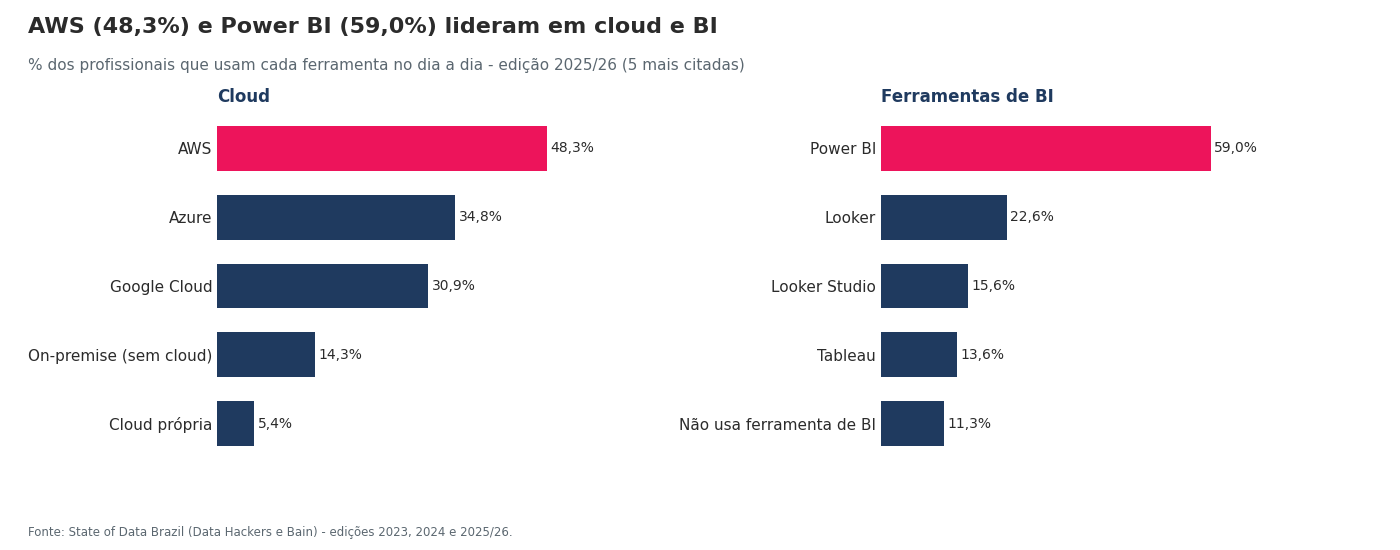

In [11]:
# Cloud e ferramentas de BI na edição mais recente
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.5), gridspec_kw={"wspace": 0.75})
for ax, tema, titulo in [(ax1, "Cloud", "Cloud"), (ax2, "Ferramentas de BI", "Ferramentas de BI")]:
    df = (tecnologias[(tecnologias["tema"] == tema) & (tecnologias["ano_pesquisa"] == "2025-2026")]
          .sort_values("percentual", ascending=False).head(5))
    barras_horizontais(ax, [quebrar(rotulo(t), 26) for t in df["tecnologia"]], df["percentual"].tolist())
    ax.set_title(titulo, loc="left", fontsize=12, fontweight="bold", color=AZUL)

nuvem = tecnologias[(tecnologias["tema"] == "Cloud") & (tecnologias["ano_pesquisa"] == "2025-2026")].sort_values("percentual", ascending=False).iloc[0]
bi = tecnologias[(tecnologias["tema"] == "Ferramentas de BI") & (tecnologias["ano_pesquisa"] == "2025-2026")].sort_values("percentual", ascending=False).iloc[0]
finalizar(fig,
          f"{rotulo(nuvem['tecnologia'])} ({pct(nuvem['percentual'])}) e {rotulo(bi['tecnologia'])} ({pct(bi['percentual'])}) lideram em cloud e BI",
          "% dos profissionais que usam cada ferramenta no dia a dia - edição 2025/26 (5 mais citadas)",
          "q4_cloud_bi")
%matplot plt

## 8. Q5 - Qual é o índice de adoção de IA e seu impacto?

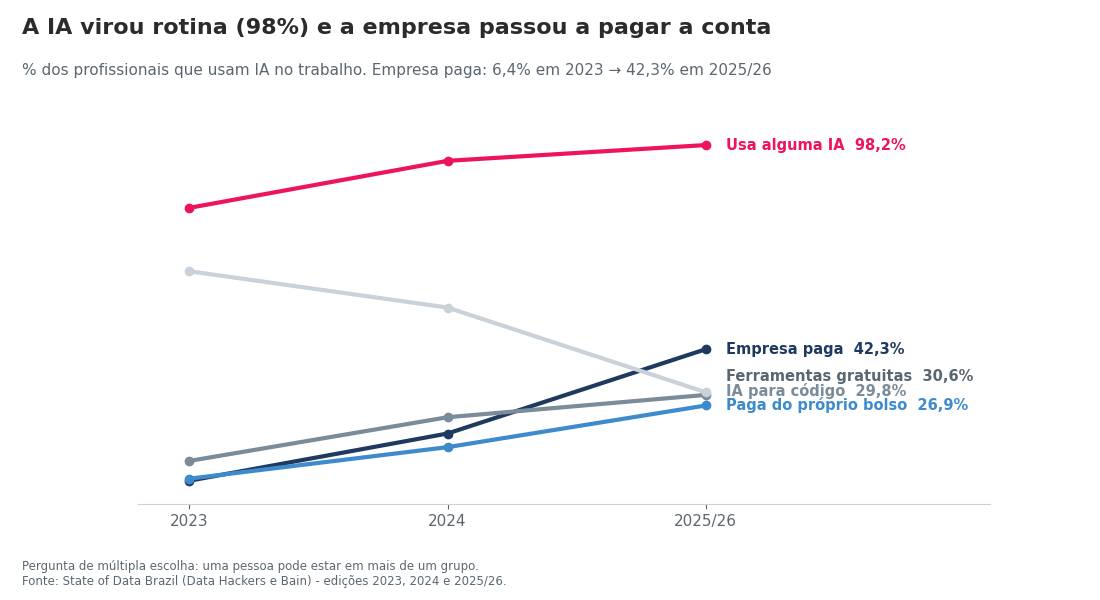

In [12]:
# Evolução do uso de IA no trabalho
adocao = gold("adocao_ia")
df = adocao[adocao["recorte_tipo"] == "Geral"]
tabela = df.pivot(index="indicador", columns="ano_pesquisa", values="percentual")[ANOS]
series = {"Usa alguma IA": ROSA, "Empresa paga": AZUL, "Paga do próprio bolso": "#3D8BCD",
          "IA para código": CINZA_MEDIO, "Ferramentas gratuitas": CINZA_CLARO}

fig, ax = plt.subplots(figsize=(11, 6))
x = list(range(len(ANOS)))
fim = espacar([tabela.loc[i, "2025-2026"] for i in series])
for (indicador, cor), y_fim in zip(series.items(), fim):
    valores = tabela.loc[indicador].tolist()
    ax.plot(x, valores, marker="o", linewidth=3, color=cor)
    ax.text(x[-1] + 0.08, y_fim, f"{indicador}  {pct(valores[-1])}", va="center",
            fontsize=10.5, color=cor if cor != CINZA_CLARO else CINZA_TEXTO, fontweight="bold")
ax.set_xticks(x)
ax.set_xticklabels([ROTULO_ANO[a] for a in ANOS])
ax.set_xlim(-0.2, 3.1)
ax.set_ylim(0, 105)
ax.yaxis.set_visible(False)
ax.spines["left"].set_visible(False)

usa = tabela.loc["Usa alguma IA"]
paga = tabela.loc["Empresa paga"]
finalizar(fig,
          f"A IA virou rotina ({usa['2025-2026']:.0f}%) e a empresa passou a pagar a conta",
          f"% dos profissionais que usam IA no trabalho. Empresa paga: {pct(paga['2023'])} em 2023 → {pct(paga['2025-2026'])} em 2025/26",
          "q5_adocao_ia",
          nota="Pergunta de múltipla escolha: uma pessoa pode estar em mais de um grupo.")
%matplot plt

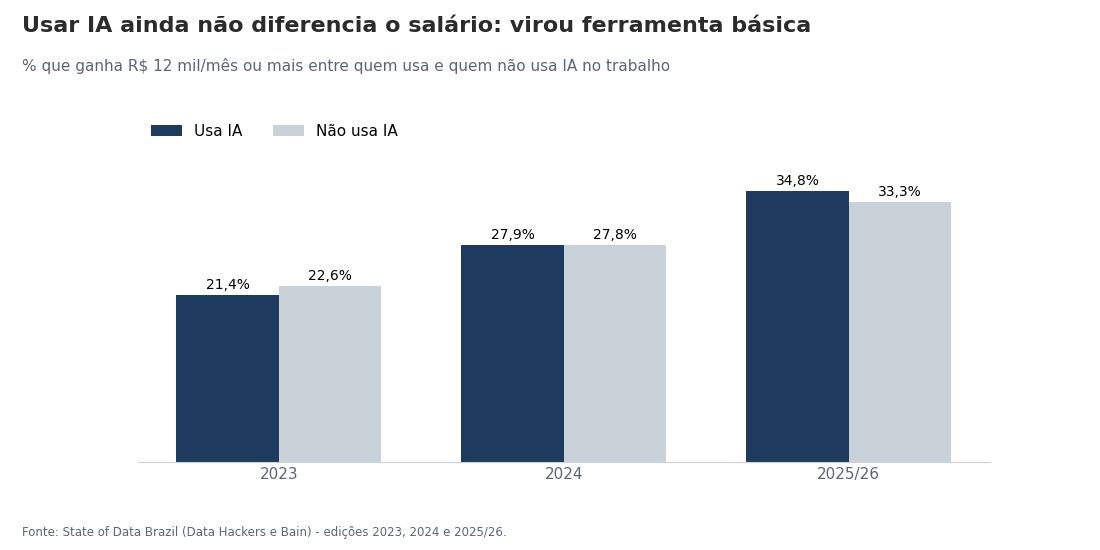

In [13]:
# Uso de IA x remuneração
df = comparacoes[comparacoes["dimensao"] == "Uso de IA"]
tabela = df.pivot(index="ano_pesquisa", columns="categoria", values="pct_12k_mais").reindex(ANOS)

fig, ax = plt.subplots(figsize=(11, 5.5))
x = list(range(len(ANOS)))
largura = 0.36
ax.bar([i - largura / 2 for i in x], tabela["Usa IA"], width=largura, color=AZUL, label="Usa IA")
ax.bar([i + largura / 2 for i in x], tabela["Não usa IA"], width=largura, color=CINZA_CLARO, label="Não usa IA")
for i in x:
    ax.text(i - largura / 2, tabela["Usa IA"].iloc[i] + 0.8, pct(tabela["Usa IA"].iloc[i]), ha="center", fontsize=10)
    ax.text(i + largura / 2, tabela["Não usa IA"].iloc[i] + 0.8, pct(tabela["Não usa IA"].iloc[i]), ha="center", fontsize=10)
ax.set_xticks(x)
ax.set_xticklabels([ROTULO_ANO[a] for a in ANOS])
ax.set_ylim(0, tabela.max().max() * 1.3)
ax.yaxis.set_visible(False)
ax.spines["left"].set_visible(False)
ax.tick_params(axis="x", length=0)
ax.legend(loc="upper left", frameon=False, ncol=2)

finalizar(fig,
          "Usar IA ainda não diferencia o salário: virou ferramenta básica",
          f"% que ganha {RS} 12 mil/mês ou mais entre quem usa e quem não usa IA no trabalho",
          "q5_ia_salario")
%matplot plt

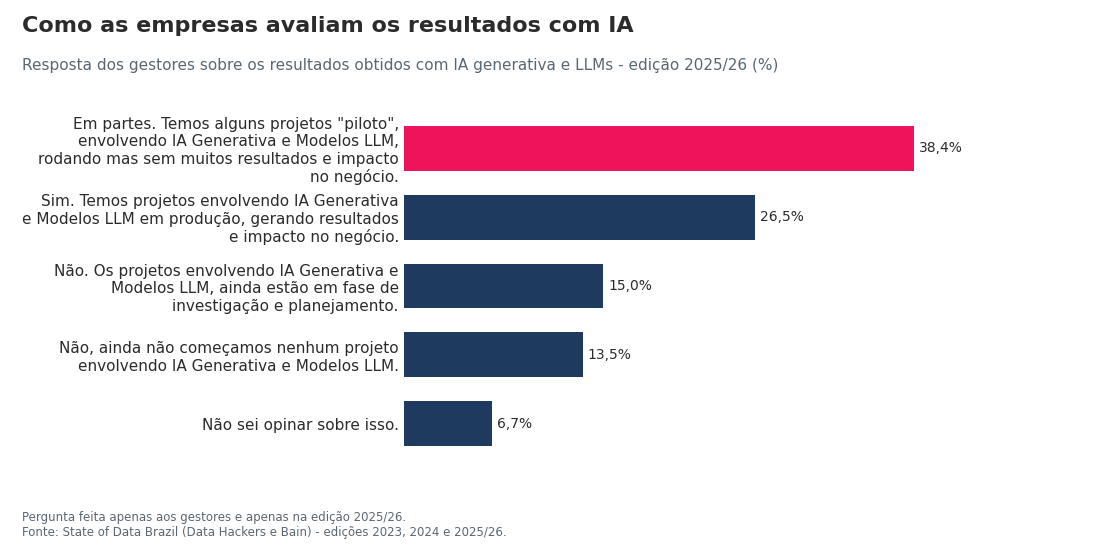

In [14]:
# Resultados que as empresas obtêm com IA (visão dos gestores)
ia_empresas = gold("ia_empresas")
df = (ia_empresas[ia_empresas["pergunta"] == "Resultados com IA na empresa (gestores)"]
      .sort_values("percentual", ascending=False))

fig, ax = plt.subplots(figsize=(11, 5.5))
barras_horizontais(ax, [quebrar(rotulo(o), 45) for o in df["opcao"]], df["percentual"].tolist())
finalizar(fig,
          "Como as empresas avaliam os resultados com IA",
          "Resposta dos gestores sobre os resultados obtidos com IA generativa e LLMs - edição 2025/26 (%)",
          "q5_resultados_ia",
          nota="Pergunta feita apenas aos gestores e apenas na edição 2025/26.")
%matplot plt

## 9. Q6 - Existem diferenças entre regiões, senioridades ou modelos de trabalho?

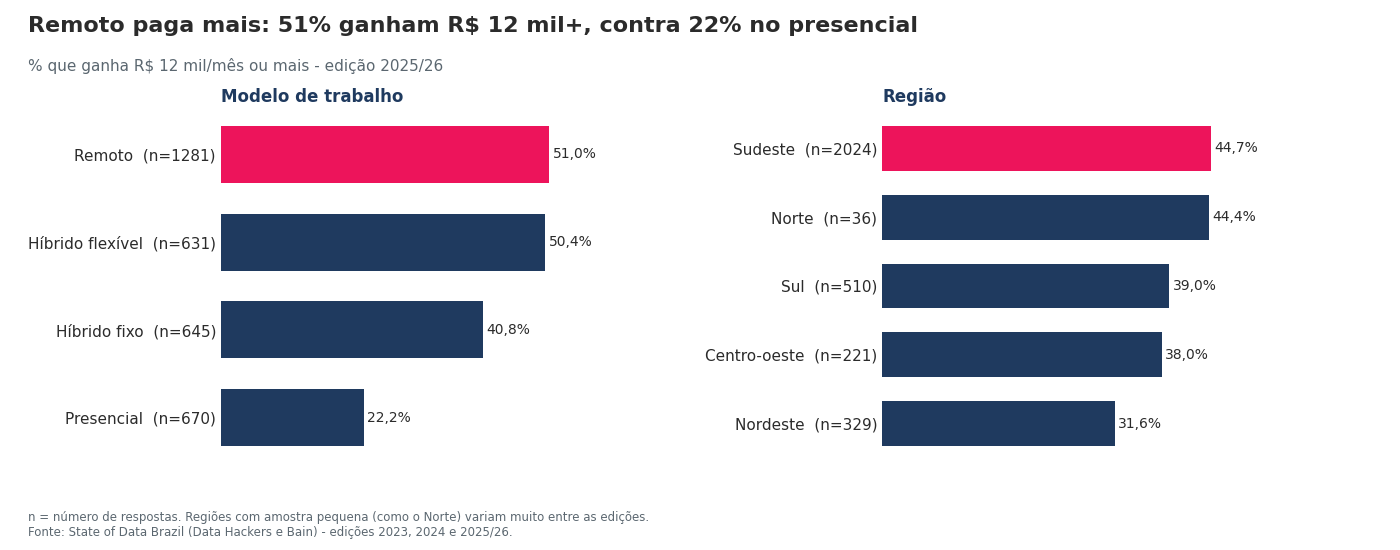

In [15]:
# Remuneração por modelo de trabalho e por região
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.5), gridspec_kw={"wspace": 0.75})
for ax, dimensao in [(ax1, "Modelo de trabalho"), (ax2, "Região")]:
    df = (comparacoes[(comparacoes["dimensao"] == dimensao) & (comparacoes["ano_pesquisa"] == "2025-2026")]
          .sort_values("pct_12k_mais", ascending=False))
    rotulos = [f"{c}  (n={n})" for c, n in zip(df["categoria"], df["respostas"])]
    barras_horizontais(ax, rotulos, df["pct_12k_mais"].tolist())
    ax.set_title(dimensao, loc="left", fontsize=12, fontweight="bold", color=AZUL)

modelos = comparacoes[(comparacoes["dimensao"] == "Modelo de trabalho") & (comparacoes["ano_pesquisa"] == "2025-2026")].set_index("categoria")["pct_12k_mais"]
finalizar(fig,
          f"Remoto paga mais: {modelos['Remoto']:.0f}% ganham {RS} 12 mil+, contra {modelos['Presencial']:.0f}% no presencial",
          f"% que ganha {RS} 12 mil/mês ou mais - edição 2025/26",
          "q6_modelo_regiao",
          nota="n = número de respostas. Regiões com amostra pequena (como o Norte) variam muito entre as edições.")
%matplot plt

## 10. Q7 - Oportunidades e desafios para empresas que querem investir em dados e IA

As duas perguntas abaixo foram respondidas pelos gestores. Os nomes das opções são das colunas da pesquisa.

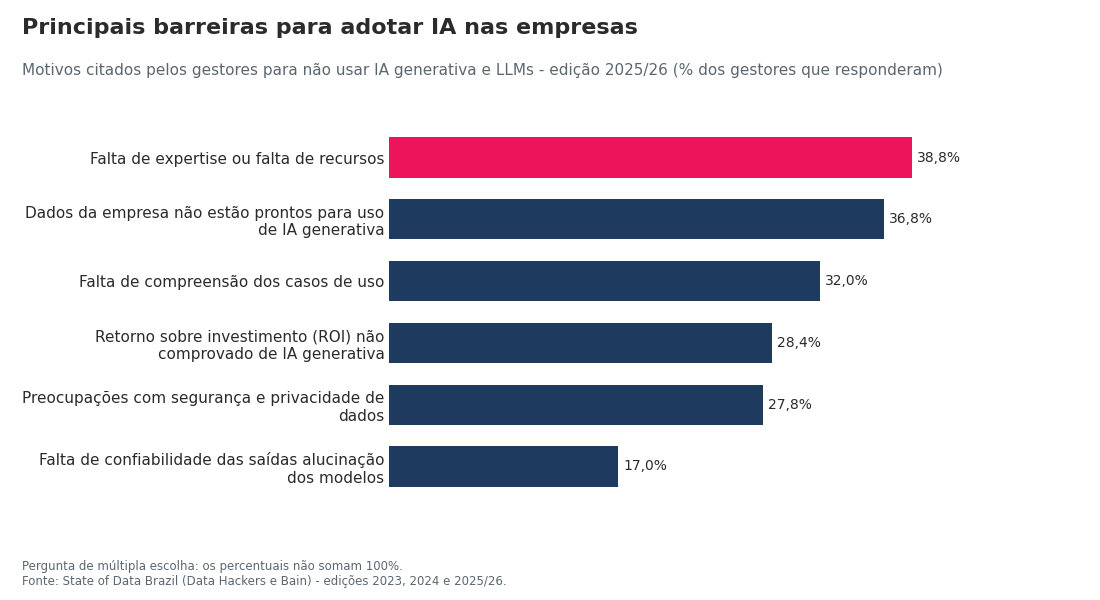

In [16]:
# Desafios: motivos para não usar IA
df = (ia_empresas[(ia_empresas["pergunta"] == "Motivos para não usar IA (gestores)") & (ia_empresas["ano_pesquisa"] == "2025-2026")]
      .sort_values("percentual", ascending=False).head(6))

fig, ax = plt.subplots(figsize=(11, 6))
barras_horizontais(ax, [quebrar(rotulo(o), 45) for o in df["opcao"]], df["percentual"].tolist())
finalizar(fig,
          "Principais barreiras para adotar IA nas empresas",
          "Motivos citados pelos gestores para não usar IA generativa e LLMs - edição 2025/26 (% dos gestores que responderam)",
          "q7_barreiras_ia",
          nota="Pergunta de múltipla escolha: os percentuais não somam 100%.")
%matplot plt

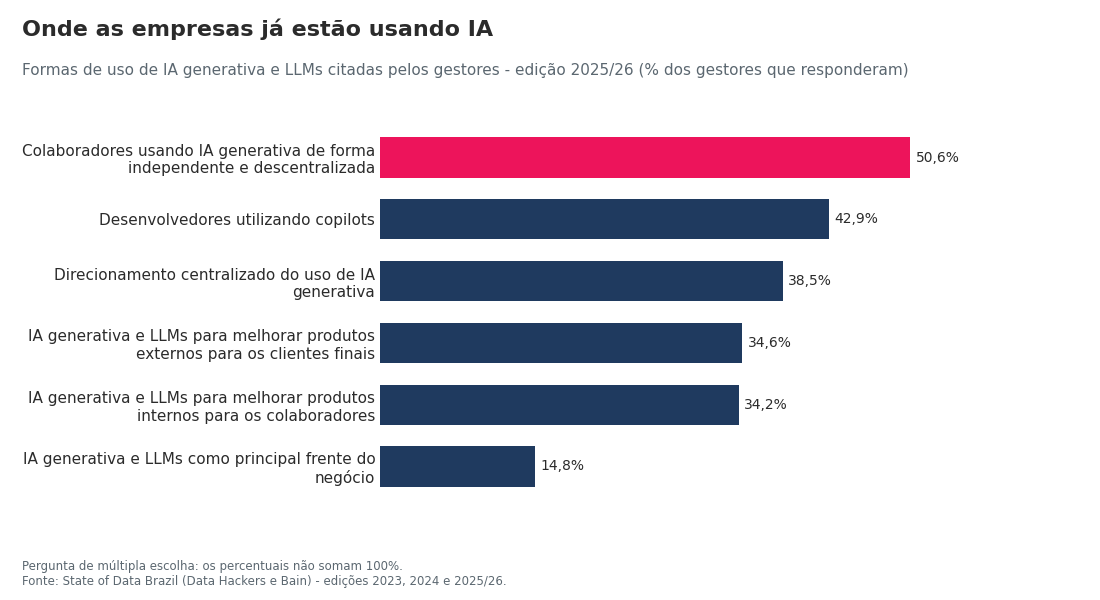

In [17]:
# Oportunidades: como as empresas já usam IA
df = (ia_empresas[(ia_empresas["pergunta"] == "Uso de IA na empresa (gestores)") & (ia_empresas["ano_pesquisa"] == "2025-2026")]
      .sort_values("percentual", ascending=False).head(6))

fig, ax = plt.subplots(figsize=(11, 6))
barras_horizontais(ax, [quebrar(rotulo(o), 45) for o in df["opcao"]], df["percentual"].tolist())
finalizar(fig,
          "Onde as empresas já estão usando IA",
          "Formas de uso de IA generativa e LLMs citadas pelos gestores - edição 2025/26 (% dos gestores que responderam)",
          "q7_uso_ia_empresas",
          nota="Pergunta de múltipla escolha: os percentuais não somam 100%.")
%matplot plt

## 11. Conferência dos arquivos gerados

In [18]:
resposta = s3.list_objects_v2(Bucket=BUCKET, Prefix=PREFIXO_GRAFICOS)
arquivos = sorted(o["Key"] for o in resposta.get("Contents", []))
for chave in arquivos:
    print(f"s3://{BUCKET}/{chave}")
print(f"\n{len(arquivos)} gráficos gerados.")

s3://teste-fiap-fase3/relatorio/graficos/q1_cargos.png
s3://teste-fiap-fase3/relatorio/graficos/q1_senioridade.png
s3://teste-fiap-fase3/relatorio/graficos/q1_situacao_trabalho.png
s3://teste-fiap-fase3/relatorio/graficos/q2_perfis_valorizados.png
s3://teste-fiap-fase3/relatorio/graficos/q2_salario_senioridade.png
s3://teste-fiap-fase3/relatorio/graficos/q3_diferenca_salarial_genero.png
s3://teste-fiap-fase3/relatorio/graficos/q3_mulheres_senioridade.png
s3://teste-fiap-fase3/relatorio/graficos/q4_cloud_bi.png
s3://teste-fiap-fase3/relatorio/graficos/q4_linguagens.png
s3://teste-fiap-fase3/relatorio/graficos/q5_adocao_ia.png
s3://teste-fiap-fase3/relatorio/graficos/q5_ia_salario.png
s3://teste-fiap-fase3/relatorio/graficos/q5_resultados_ia.png
s3://teste-fiap-fase3/relatorio/graficos/q6_modelo_regiao.png
s3://teste-fiap-fase3/relatorio/graficos/q7_barreiras_ia.png
s3://teste-fiap-fase3/relatorio/graficos/q7_uso_ia_empresas.png

15 gráficos gerados.
